# Day 1: Python basics for research data
Run each grey box with **Shift + Enter**. Read the comments (lines starting with `#`). Change things and re-run; you can't break anything.

## 1. Python as a calculator, and variables

In [11]:
# a variable stores a value
n_patients = 9
n_sessions = 2
total_recordings = n_patients * n_sessions
print('Total recordings:', total_recordings)

Total recordings: 18


## 2. Lists and loops

In [12]:
# a list holds several values
ages = [64, 71, 58, 69, 75, 62, 67, 70, 66]

print('Number of patients:', len(ages))
print('Mean age:', sum(ages) / len(ages))

# a loop repeats an action for each item
for age in ages:
    if age >= 70:
        print(age, 'is 70 or over')

Number of patients: 9
Mean age: 66.88888888888889
71 is 70 or over
75 is 70 or over
70 is 70 or over


## 3. Tables with pandas
pandas is Python's version of an Excel sheet. Researchers use it for almost everything.

In [13]:
import pandas as pd
import numpy as np

rng = np.random.default_rng(1)   # makes the fake data the same every time

# a pretend dataset: 20 patients and 20 controls, each with a beta power value
df = pd.DataFrame({
    'participant': [f'sub-{i:02d}' for i in range(1, 41)],
    'group': ['patient'] * 20 + ['control'] * 20,
    'age': rng.integers(55, 80, 40),
    'beta_power': np.concatenate([rng.normal(1.3, 0.3, 20), rng.normal(1.0, 0.3, 20)]),
})

df.head()   # shows the first 5 rows

,participant,group,age,beta_power
0,sub-01,patient,66,1.302443
1,sub-02,patient,67,1.217319
2,sub-03,patient,73,1.688219
3,sub-04,patient,78,1.602017
4,sub-05,patient,55,0.486651


In [14]:
# summary statistics for each group
df.groupby('group')['beta_power'].describe()

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
control,20.0,0.954340,0.215523,0.625375,0.784907,0.974453,1.116722,1.274340
patient,20.0,1.290435,0.363403,0.486651,1.166457,1.317573,1.495238,1.935352


In [15]:
# select rows: only patients older than 70
df[(df['group'] == 'patient') & (df['age'] > 70)]

,participant,group,age,beta_power
2,sub-03,patient,73,1.688219
3,sub-04,patient,78,1.602017
6,sub-07,patient,75,1.247568
7,sub-08,patient,78,1.173343
10,sub-11,patient,76,1.935352
13,sub-14,patient,75,1.912831
16,sub-17,patient,71,1.145798


## 4. Saving and loading a CSV file

In [16]:
df.to_csv('practice_data.csv', index=False)

loaded = pd.read_csv('practice_data.csv')
print(loaded.shape, '-> rows, columns')

(40, 4) -> rows, columns


## 5. Plotting with matplotlib

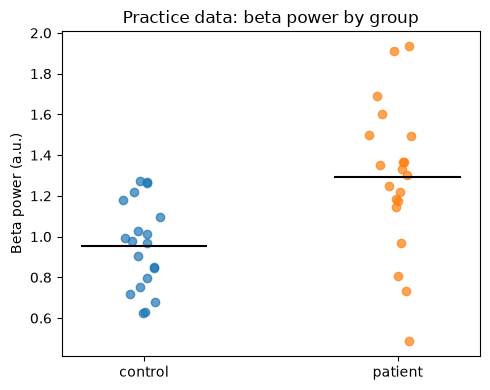

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
for i, (name, sub) in enumerate(df.groupby('group')):
    x = np.full(len(sub), i) + rng.normal(0, 0.05, len(sub))   # small jitter so dots don't overlap
    ax.scatter(x, sub['beta_power'], alpha=0.7)
    ax.hlines(sub['beta_power'].mean(), i - 0.25, i + 0.25, color='black')
ax.set_xticks([0, 1])
ax.set_xticklabels(['control', 'patient'])
ax.set_ylabel('Beta power (a.u.)')
ax.set_title('Practice data: beta power by group')
plt.tight_layout()
plt.show()

## 6. A simple statistical test

In [18]:
import pingouin as pg

patients = df.loc[df['group'] == 'patient', 'beta_power']
controls = df.loc[df['group'] == 'control', 'beta_power']

pg.ttest(patients, controls)   # t-test with effect size (cohen-d) and confidence interval

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,3.557482,38,two-sided,0.001024,"[0.14, 0.53]",1.124974,0.933999,30.575


## Your mini challenge
1. Add a column `older = age >= 70` (hint: `df['older'] = df['age'] >= 70`).
2. Compare mean beta power for older vs younger participants.
3. Make a histogram of age with `df['age'].hist()`.

When done, save this notebook. It becomes your first file on GitHub.

In [19]:
df['older'] = df['age'] >= 70
df.groupby('older')['beta_power'].mean()

older
False    1.056642
True     1.244486
Name: beta_power, dtype: float64

<Axes: >

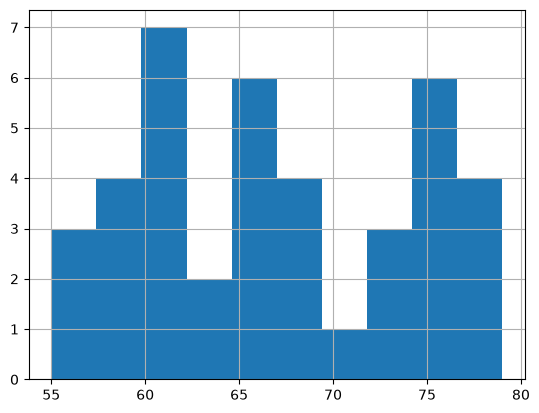

In [20]:
df['age'].hist()